In [1]:
import os
import sys
import platform
import shutil
import psutil
import pandas as pd
import numpy as np

print("=" * 50)
print("RAILPULSE AI - SYSTEM AUDIT")
print("=" * 50)

print("Python Version:", sys.version)
print("Platform:", platform.platform())

memory = psutil.virtual_memory()

print("\nRAM INFORMATION")
print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")

disk = shutil.disk_usage(os.getcwd())

print("\nDISK INFORMATION")
print("Total Disk:", round(disk.total / (1024**3), 2), "GB")
print("Free Disk:", round(disk.free / (1024**3), 2), "GB")

print("\nLIBRARY VERSIONS")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("\nPROJECT DIRECTORY")
print(os.getcwd())

print("\nSYSTEM AUDIT COMPLETED")

RAILPULSE AI - SYSTEM AUDIT
Python Version: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Platform: Windows-11-10.0.26300-SP0

RAM INFORMATION
Total RAM: 7.84 GB
Available RAM: 1.97 GB

DISK INFORMATION
Total Disk: 237.03 GB
Free Disk: 34.53 GB

LIBRARY VERSIONS
Pandas: 3.0.0
NumPy: 2.4.1

PROJECT DIRECTORY
C:\Users\Login\Documents\RailPulse_AI\notebooks

SYSTEM AUDIT COMPLETED


In [2]:
import urllib.request
import zipfile
import os

base = os.path.abspath("../data/raw")
os.makedirs(base, exist_ok=True)

url = "https://codeload.github.com/KoyenaChowdhury/RSTGCN/zip/refs/heads/main"

repo_zip = os.path.join(base, "RSTGCN_repository.zip")

print("Downloading Candidate A repository...")

urllib.request.urlretrieve(url, repo_zip)

print("Download successful!")
print("Size:", round(os.path.getsize(repo_zip) / (1024**2), 2), "MB")

extract_path = os.path.join(base, "RSTGCN_repository")
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(repo_zip, "r") as z:
    z.extractall(extract_path)

print("\nRepository contents:")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        path = os.path.join(root, file)
        print(file, "|", round(os.path.getsize(path) / (1024**2), 2), "MB")

Download successful!
Size: 22.74 MB

Repository contents:
Indian-Railway-Network-and-Delays.zip | 22.93 MB
README.md | 0.01 MB


In [3]:
import os
import zipfile
import glob

base = os.path.abspath("../data/raw/RSTGCN_repository")

# Locate nested ZIP and README
zip_files = glob.glob(base + "/**/*.zip", recursive=True)
readme_files = glob.glob(base + "/**/README.md", recursive=True)

print("NESTED ZIP FILES")
for f in zip_files:
    print(f, round(os.path.getsize(f)/1024**2, 2), "MB")

print("\nREADME CONTENT")

for f in readme_files:
    with open(f, "r", encoding="utf-8") as file:
        print(file.read())

print("\nACTUAL DATASET FILE INVENTORY")

for zpath in zip_files:
    with zipfile.ZipFile(zpath, "r") as z:
        for item in z.infolist():
            if not item.is_dir():
                print(
                    item.filename,
                    "|",
                    round(item.file_size/1024**2, 3),
                    "MB"
                )

NESTED ZIP FILES
C:\Users\Login\Documents\RailPulse_AI\data\raw\RSTGCN_repository\RSTGCN-main\Indian-Railway-Network-and-Delays.zip 22.93 MB

README CONTENT
# Indian Railway Network and Delays

Datasets for Indian Railway network topology, station-to-zone mappings, scheduled train routes, and observed train delays — including full operational data for September 2024.

## Overview

This repository provides datasets representing the **Indian Railway Network (IRN)** at the station, network, and train-route levels, spanning **4,735 stations across 17 zones** — one of the most comprehensive Indian railway datasets curated for research to date. The datasets combine railway network connectivity, station-to-zone mappings, scheduled train routes, and observed train arrival/departure delays, as described in the following paper:

> **RSTGCN: Railway-centric Spatio-Temporal Graph Convolutional Network for Train Delay Prediction**
> 
> **Koyena Chowdhury**, Paramita Koley, Abhijnan Chakraborty, Sap

In [4]:
import os
import zipfile

base = os.path.abspath("../data/raw/RSTGCN_repository")

nested_zip = os.path.join(
    base,
    "RSTGCN-main",
    "Indian-Railway-Network-and-Delays.zip"
)

extract_to = os.path.abspath("../data/interim/RSTGCN")

os.makedirs(extract_to, exist_ok=True)

with zipfile.ZipFile(nested_zip, "r") as z:
    z.extractall(extract_to)

print("EXTRACTION SUCCESSFUL\n")

for root, dirs, files in os.walk(extract_to):
    for file in files:
        path = os.path.join(root, file)
        print(file, round(os.path.getsize(path)/1024**2, 2), "MB")

EXTRACTION SUCCESSFUL

IRN_edges.csv 0.13 MB
stations_zones_mapping.json 0.06 MB
train_delays_Sep2024.json 89.78 MB
train_routes_delays_Sep2024.csv 80.99 MB
train_routes_Sep2024.csv 5.11 MB


In [5]:
import pandas as pd
import os
import glob

data_dir = os.path.abspath(
    "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"
)

csv_files = glob.glob(data_dir + "/*.csv")

for file in csv_files:
    print("\n" + "="*65)
    print("FILE:", os.path.basename(file))

    df = pd.read_csv(file, nrows=5)

    print("\nCOLUMNS:")
    print(df.columns.tolist())

    print("\nSAMPLE RECORDS:")
    print(df.to_string(index=False))


FILE: IRN_edges.csv

COLUMNS:
['from', 'to', 'distance', 'ntrains']

SAMPLE RECORDS:
from   to  distance  ntrains
AADR  UHL        28       10
AADR DLPC        15        6
 AAG  WKA         6        1
 AAG MKPT         7        1
 AAL  BUH         9       14

FILE: train_routes_delays_Sep2024.csv

COLUMNS:
['train', 'date', 'station', 'sch_arr', 'act_arr', 'arr_delay', 'sch_dep', 'act_dep', 'dep_delay']

SAMPLE RECORDS:
 train       date station  sch_arr  act_arr  arr_delay  sch_dep  act_dep  dep_delay
 12303 2024-09-02     HWH 08:00 AM 08:01 AM        0.0 08:00 AM 08:01 AM        0.0
 12303 2024-09-02     BWN 09:05 AM 09:20 AM       15.0 09:08 AM 09:23 AM       15.0
 12303 2024-09-02     DGR 09:57 AM 10:00 AM        3.0 09:59 AM 10:02 AM        3.0
 12303 2024-09-02     ASN 10:32 AM 10:34 AM        2.0 10:37 AM 10:39 AM        2.0
 12303 2024-09-02     CRJ 11:00 AM 11:04 AM        4.0 11:02 AM 11:06 AM        4.0

FILE: train_routes_Sep2024.csv

COLUMNS:
['stnSerialNumber', 'trainNum

In [6]:

import pandas as pd
import numpy as np
import os
import sqlite3

data_dir = os.path.abspath(
    "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"
)

delay_file = os.path.join(
    data_dir, "train_routes_delays_Sep2024.csv"
)

route_file = os.path.join(
    data_dir, "train_routes_Sep2024.csv"
)

print("=" * 65)
print("RAILPULSE AI - CANDIDATE A DATA QUALITY AUDIT")
print("=" * 65)

# 1. Inspect route dataset
routes = pd.read_csv(route_file)

routes["trainNumber"] = (
    routes["trainNumber"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
)
routes["station_code"] = routes["station_code"].astype(str).str.strip()

routes["stnSerialNumber"] = pd.to_numeric(
    routes["stnSerialNumber"], errors="coerce"
)

route_keys = set(zip(
    routes["trainNumber"],
    routes["station_code"]
))

print("\n1. ROUTE DATASET")
print("Rows:", len(routes))
print("Unique trains:", routes["trainNumber"].nunique())
print("Unique stations:", routes["station_code"].nunique())
print("Duplicate train-station keys:",
      routes.duplicated(["trainNumber", "station_code"]).sum())
print("Missing values:\n", routes.isna().sum())

# 2. Prepare disk-based duplicate checking
db_path = os.path.join(
    "../", "candidate_a_audit.sqlite"
)

conn = sqlite3.connect(db_path)

conn.execute("DROP TABLE IF EXISTS observed_keys")

conn.execute("""
CREATE TABLE observed_keys (
    train TEXT,
    journey_date TEXT,
    station TEXT,
    PRIMARY KEY (train, journey_date, station)
)
""")

# 3. Stream delay dataset
total_rows = 0
duplicate_keys = 0
matched_rows = 0
unmatched_rows = 0
invalid_keys = 0

missing_counts = None

trains = set()
stations = set()
dates = set()

delay_count = 0
delay_sum = 0
delay_min = float("inf")
delay_max = float("-inf")
delay_missing = 0

date_min = None
date_max = None

for chunk in pd.read_csv(delay_file, chunksize=100000):

    total_rows += len(chunk)

    # Missing values
    counts = chunk.isna().sum()

    if missing_counts is None:
        missing_counts = counts
    else:
        missing_counts += counts

    # Normalize identifiers
    chunk["train"] = (
        chunk["train"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    )
    chunk["station"] = chunk["station"].astype(str).str.strip()

    # Unique identifiers
    trains.update(chunk["train"].dropna().unique())
    stations.update(chunk["station"].dropna().unique())
    dates.update(chunk["date"].dropna().unique())

    # Date coverage
    parsed_dates = pd.to_datetime(
        chunk["date"], errors="coerce"
    )

    if parsed_dates.notna().any():
        current_min = parsed_dates.min()
        current_max = parsed_dates.max()

        date_min = current_min if date_min is None else min(date_min, current_min)
        date_max = current_max if date_max is None else max(date_max, current_max)

    # Arrival delay statistics
    delays = pd.to_numeric(
        chunk["arr_delay"], errors="coerce"
    )

    delay_missing += delays.isna().sum()

    valid = delays.dropna()

    if len(valid):
        delay_count += len(valid)
        delay_sum += valid.sum()
        delay_min = min(delay_min, valid.min())
        delay_max = max(delay_max, valid.max())

    # Check route matching
    keys = list(zip(chunk["train"], chunk["station"]))

    matches = sum(key in route_keys for key in keys)

    matched_rows += matches
    unmatched_rows += len(keys) - matches

    # Exact duplicate key detection using SQLite
    valid_keys = [
        (str(t), str(d), str(s))
        for t, d, s in zip(
            chunk["train"],
            chunk["date"],
            chunk["station"]
        )
        if pd.notna(t) and pd.notna(d) and pd.notna(s)
    ]

    invalid_keys += len(chunk) - len(valid_keys)

    before = conn.total_changes

    conn.executemany(
        "INSERT OR IGNORE INTO observed_keys VALUES (?, ?, ?)",
        valid_keys
    )

    duplicate_keys += (
        len(valid_keys) - (conn.total_changes - before)
    )

conn.commit()
conn.close()

# 4. Final report
print("\n2. DELAY DATASET")
print("Total rows:", total_rows)
print("Unique trains:", len(trains))
print("Unique stations:", len(stations))
print("Unique dates:", len(dates))
print("Date range:", date_min, "to", date_max)

print("\n3. MISSING VALUES")
print(missing_counts)

print("\n4. DUPLICATE CHECK")
print("Duplicate train-date-station records:", duplicate_keys)
print("Records with missing keys:", invalid_keys)

print("\n5. ARRIVAL DELAY STATISTICS")
print("Valid delays:", delay_count)
print("Missing/invalid delays:", delay_missing)

if delay_count:
    print("Mean delay:", round(delay_sum / delay_count, 2))
    print("Minimum delay:", delay_min)
    print("Maximum delay:", delay_max)

print("\n6. ROUTE JOIN FEASIBILITY")
print("Matched delay records:", matched_rows)
print("Unmatched delay records:", unmatched_rows)

if total_rows:
    print(
        "Route match percentage:",
        round(matched_rows / total_rows * 100, 2), "%"
    )

print("\n" + "=" * 65)
print("CANDIDATE A INITIAL AUDIT COMPLETED")
print("=" * 65)


RAILPULSE AI - CANDIDATE A DATA QUALITY AUDIT

1. ROUTE DATASET
Rows: 85055
Unique trains: 3892
Unique stations: 4735
Duplicate train-station keys: 42
Missing values:
 stnSerialNumber    0
trainNumber        0
trainName          0
station_code       0
station_name       7
distance           0
arrivalTime        0
departureTime      0
dtype: int64

2. DELAY DATASET
Total rows: 1282325
Unique trains: 3892
Unique stations: 4736
Unique dates: 30
Date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00

3. MISSING VALUES
train        0
date         0
station      0
sch_arr      0
act_arr      0
arr_delay    0
sch_dep      0
act_dep      0
dep_delay    0
dtype: int64

4. DUPLICATE CHECK
Duplicate train-date-station records: 0
Records with missing keys: 0

5. ARRIVAL DELAY STATISTICS
Valid delays: 1282325
Missing/invalid delays: 0
Mean delay: 32.9
Minimum delay: 0.0
Maximum delay: 4336.0

6. ROUTE JOIN FEASIBILITY
Matched delay records: 1282263
Unmatched delay records: 62
Route match percentage

In [7]:

import pandas as pd
import os

data_dir = os.path.abspath(
    "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"
)

route_file = os.path.join(data_dir, "train_routes_Sep2024.csv")
delay_file = os.path.join(data_dir, "train_routes_delays_Sep2024.csv")

routes = pd.read_csv(route_file)

routes["trainNumber"] = routes["trainNumber"].astype(str).str.strip()
routes["station_code"] = routes["station_code"].astype(str).str.strip()

# 1. Investigate duplicate route keys
duplicates = routes[
    routes.duplicated(
        ["trainNumber", "station_code"],
        keep=False
    )
].sort_values(["trainNumber", "station_code", "stnSerialNumber"])

print("=" * 60)
print("1. DUPLICATE ROUTE RECORDS")
print("=" * 60)
print("Duplicate rows:", len(duplicates))
print(duplicates.to_string(index=False))

# Check duplicate route positions
print("\nDuplicate train + sequence combinations:")
print(
    routes.duplicated(
        ["trainNumber", "stnSerialNumber"]
    ).sum()
)

# 2. Identify unmatched delay records
route_keys = set(zip(
    routes["trainNumber"],
    routes["station_code"]
))

unmatched_samples = []

# 3. Investigate delay consistency
mismatch_samples = []
comparison_count = 0
mismatch_count = 0
parse_failures = 0

for chunk in pd.read_csv(delay_file, chunksize=100000):

    chunk["train"] = chunk["train"].astype(str).str.strip()
    chunk["station"] = chunk["station"].astype(str).str.strip()

    # Unmatched records
    keys = list(zip(chunk["train"], chunk["station"]))

    for i, key in enumerate(keys):
        if key not in route_keys and len(unmatched_samples) < 20:
            unmatched_samples.append(chunk.iloc[i].to_dict())

    # Compare scheduled and actual arrival times
    scheduled = pd.to_datetime(
        chunk["sch_arr"],
        format="%I:%M %p",
        errors="coerce"
    )

    actual = pd.to_datetime(
        chunk["act_arr"],
        format="%I:%M %p",
        errors="coerce"
    )

    reported = pd.to_numeric(
        chunk["arr_delay"],
        errors="coerce"
    )

    valid = scheduled.notna() & actual.notna() & reported.notna()

    difference = (
        (actual - scheduled).dt.total_seconds() / 60
    )

    difference = difference.where(difference >= 0, difference + 1440)

    mismatches = valid & ((difference - reported).abs() > 1)

    comparison_count += valid.sum()
    mismatch_count += mismatches.sum()
    parse_failures += (~valid).sum()

    if len(mismatch_samples) < 15:
        examples = chunk.loc[
            mismatches,
            ["train", "date", "station", "sch_arr",
             "act_arr", "arr_delay"]
        ].head(15 - len(mismatch_samples))

        mismatch_samples.extend(examples.to_dict("records"))

print("\n" + "=" * 60)
print("2. UNMATCHED DELAY RECORDS")
print("=" * 60)
print("First unmatched records:")
print(pd.DataFrame(unmatched_samples).to_string(index=False))

print("\n" + "=" * 60)
print("3. ARRIVAL DELAY CONSISTENCY")
print("=" * 60)
print("Comparable records:", comparison_count)
print("Mismatches beyond 1 minute:", mismatch_count)
print("Unparseable records:", parse_failures)

print("\nMismatch examples:")
print(pd.DataFrame(mismatch_samples).to_string(index=False))

print("\nANOMALY INVESTIGATION COMPLETED")


1. DUPLICATE ROUTE RECORDS
Duplicate rows: 84
 stnSerialNumber trainNumber        trainName station_code     station_name  distance arrivalTime departureTime
              31       16546 Snnr Ypr Express          AJP         Ajjampur       402    03:11 AM      03:12 AM
              71       16546 Snnr Ypr Express          AJP         Ajjampur       402    03:11 AM      03:12 AM
              25       16546 Snnr Ypr Express          AMC       Amritapura       338    01:45 AM      01:46 AM
              65       16546 Snnr Ypr Express          AMC       Amritapura       338    01:45 AM      01:46 AM
              34       16546 Snnr Ypr Express          ASK         Arsikere       464    05:00 AM      05:05 AM
              74       16546 Snnr Ypr Express          ASK         Arsikere       464    05:00 AM      05:05 AM
              23       16546 Snnr Ypr Express         BAHI      Balenahalli       297    01:03 AM      01:04 AM
              63       16546 Snnr Ypr Express         BAHI

In [8]:

import pandas as pd
import os
import numpy as np

data_dir = os.path.abspath(
    "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"
)

routes = pd.read_csv(
    os.path.join(data_dir, "train_routes_Sep2024.csv")
)

delays = pd.read_csv(
    os.path.join(data_dir, "train_routes_delays_Sep2024.csv")
)

# A. Inspect train 16546
print("=" * 65)
print("A. TRAIN 16546 ROUTE INVESTIGATION")
print("=" * 65)

t = routes[
    routes["trainNumber"].astype(str) == "16546"
].sort_values("stnSerialNumber")

print("Total route rows:", len(t))
print(t[
    ["stnSerialNumber", "station_code",
     "station_name", "distance", "arrivalTime"]
].to_string(index=False))

# B. Inspect train 13212
print("\n" + "=" * 65)
print("B. TRAIN 13212 - TMA INVESTIGATION")
print("=" * 65)

t = routes[
    routes["trainNumber"].astype(str) == "13212"
].sort_values("stnSerialNumber")

print("Scheduled route:")
print(t[
    ["stnSerialNumber", "station_code",
     "station_name", "distance"]
].to_string(index=False))

print("\nTMA delay observations:")
print(
    delays[
        (delays["train"].astype(str) == "13212") &
        (delays["station"] == "TMA")
    ].head(10).to_string(index=False)
)

# C. Inspect delay consistency using clock-time differences
print("\n" + "=" * 65)
print("C. ARRIVAL DELAY DISCREPANCY ANALYSIS")
print("=" * 65)

sch = pd.to_datetime(
    delays["sch_arr"], format="%I:%M %p", errors="coerce"
)

act = pd.to_datetime(
    delays["act_arr"], format="%I:%M %p", errors="coerce"
)

reported = pd.to_numeric(delays["arr_delay"], errors="coerce")

clock_difference = (
    (act - sch).dt.total_seconds() / 60
) % 1440

delta = reported - clock_difference

check = delays.copy()
check["clock_difference"] = clock_difference
check["reported_delay"] = reported
check["difference"] = delta

mismatch = check[
    check["difference"].abs() > 1
].copy()

print("Total mismatches:", len(mismatch))

print("\nMost common discrepancy values:")
print(
    mismatch["difference"]
    .round()
    .value_counts()
    .head(15)
    .to_string()
)

print("\nMismatch examples:")
print(
    mismatch[
        ["train", "date", "station", "sch_arr",
         "act_arr", "reported_delay",
         "clock_difference", "difference"]
    ].head(20).to_string(index=False)
)

print("\nDIAGNOSTIC COMPLETED")


A. TRAIN 16546 ROUTE INVESTIGATION
Total route rows: 80
 stnSerialNumber station_code     station_name  distance arrivalTime
               1         SNNR              NaN         0    05:30 AM
               2         KTGG         Karatagi        19    05:23 PM
               3         SIDG         Siddapur        31    05:39 PM
               4         SRNM    Sriramnagar H        35    05:49 PM
               5         GGVT       Gangavathi        45    05:58 PM
               6         CKBK    Chikkabenakal        58    06:19 PM
               7         JBGD      Jabbalgudda        66    06:31 PM
               8         BDGU        Budagumpa        75    06:44 PM
               9          GIN         Ginigera        84    07:10 PM
              10          MRB        Munirabad        95    07:29 PM
              11          HPT           Hospet       101    07:45 PM
              12          GNR       Gadiganuru       127    08:29 PM
              13         TNGL      Toranagallu 

In [9]:

import pandas as pd
import os

base = "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"

route_path = os.path.join(base, "train_routes_Sep2024.csv")
delay_path = os.path.join(base, "train_routes_delays_Sep2024.csv")

# Load and prepare route information
routes = pd.read_csv(route_path)

routes["trainNumber"] = routes["trainNumber"].astype(str).str.strip()
routes["station_code"] = routes["station_code"].astype(str).str.strip()

routes = routes.sort_values(
    ["trainNumber", "stnSerialNumber"]
).copy()

# Exclude confirmed duplicated route block
routes = routes[routes["trainNumber"] != "16546"].copy()

# Create next-station information
routes["next_station"] = (
    routes.groupby("trainNumber")["station_code"].shift(-1)
)

routes["next_distance"] = (
    routes.groupby("trainNumber")["distance"].shift(-1)
)

routes["distance_to_next"] = (
    routes["next_distance"] - routes["distance"]
)

routes["next_sequence"] = (
    routes.groupby("trainNumber")["stnSerialNumber"].shift(-1)
)

# Keep only valid consecutive route transitions
transitions = routes.dropna(subset=["next_station"]).copy()

print("ROUTE TRANSITION AUDIT")
print("Route rows:", len(routes))
print("Potential transitions:", len(transitions))
print("Invalid distance transitions:",
      (transitions["distance_to_next"] <= 0).sum())
print("Non-consecutive sequence transitions:",
      (transitions["next_sequence"] !=
       transitions["stnSerialNumber"] + 1).sum())

# Prepare route lookup for current and next station
route_keys = transitions[
    ["trainNumber", "station_code", "stnSerialNumber",
     "next_station", "distance_to_next"]
].copy()

# Stream delay observations
matched_current = 0
matched_next = 0
valid_pairs = 0
unmatched_current = 0
unmatched_next = 0

for chunk in pd.read_csv(
    delay_path,
    chunksize=100_000,
    dtype={"train": str, "station": str}
):
    chunk["train"] = chunk["train"].str.strip()
    chunk["station"] = chunk["station"].str.strip()

    current = chunk.merge(
        route_keys,
        left_on=["train", "station"],
        right_on=["trainNumber", "station_code"],
        how="left"
    )

    matched_current += current["next_station"].notna().sum()
    unmatched_current += current["next_station"].isna().sum()

    # Match next station observations within the same train and date
    next_lookup = chunk[
        ["train", "date", "station", "arr_delay"]
    ].rename(columns={
        "station": "next_station",
        "arr_delay": "next_arr_delay"
    })

    paired = current.merge(
        next_lookup,
        on=["train", "date", "next_station"],
        how="left"
    )

    matched_next += paired["next_arr_delay"].notna().sum()
    unmatched_next += (
        paired["next_station"].notna() &
        paired["next_arr_delay"].isna()
    ).sum()

    valid_pairs += (
        paired["next_station"].notna() &
        paired["next_arr_delay"].notna()
    ).sum()

print("\nPAIRING RESULTS")
print("Current station observations matched:", matched_current)
print("Current station observations unmatched:", unmatched_current)
print("Next station observations found:", matched_next)
print("Next station observations missing:", unmatched_next)
print("Potential valid pairs:", valid_pairs)


ROUTE TRANSITION AUDIT
Route rows: 84975
Potential transitions: 81084
Invalid distance transitions: 7
Non-consecutive sequence transitions: 2

PAIRING RESULTS
Current station observations matched: 1101643
Current station observations unmatched: 180712
Next station observations found: 1101634
Next station observations missing: 9
Potential valid pairs: 1101634


In [10]:

import pandas as pd
import os

base = "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"

routes = pd.read_csv(
    os.path.join(base, "train_routes_Sep2024.csv")
)

routes["trainNumber"] = routes["trainNumber"].astype(str).str.strip()
routes["station_code"] = routes["station_code"].astype(str).str.strip()

routes = routes[routes["trainNumber"] != "16546"].copy()
routes = routes.sort_values(["trainNumber", "stnSerialNumber"])

# 1. Check repeated station codes within the same train
duplicate_keys = routes[
    routes.duplicated(
        subset=["trainNumber", "station_code"],
        keep=False
    )
].sort_values(["trainNumber", "station_code", "stnSerialNumber"])

print("=" * 65)
print("1. REPEATED TRAIN-STATION KEYS")
print("=" * 65)
print("Rows involved:", len(duplicate_keys))
print("Unique train-station combinations:",
      duplicate_keys[["trainNumber", "station_code"]]
      .drop_duplicates().shape[0])

print("\nExamples:")
print(duplicate_keys[
    ["trainNumber", "stnSerialNumber", "station_code",
     "station_name", "distance"]
].head(30).to_string(index=False))

# 2. Inspect invalid transitions
routes["next_station"] = (
    routes.groupby("trainNumber")["station_code"].shift(-1)
)
routes["next_distance"] = (
    routes.groupby("trainNumber")["distance"].shift(-1)
)
routes["next_sequence"] = (
    routes.groupby("trainNumber")["stnSerialNumber"].shift(-1)
)

transitions = routes.dropna(subset=["next_station"]).copy()
transitions["distance_to_next"] = (
    transitions["next_distance"] - transitions["distance"]
)

invalid_distance = transitions[
    transitions["distance_to_next"] <= 0
]

invalid_sequence = transitions[
    transitions["next_sequence"] !=
    transitions["stnSerialNumber"] + 1
]

print("\n" + "=" * 65)
print("2. INVALID ROUTE TRANSITIONS")
print("=" * 65)

print("\nInvalid distances:")
print(invalid_distance[
    ["trainNumber", "stnSerialNumber", "station_code",
     "distance", "next_station", "next_distance"]
].to_string(index=False))

print("\nNon-consecutive sequences:")
print(invalid_sequence[
    ["trainNumber", "stnSerialNumber", "station_code",
     "next_sequence", "next_station"]
].to_string(index=False))

# 3. Check whether route matching creates multiple matches
route_counts = (
    routes.groupby(["trainNumber", "station_code"])
    .size()
    .reset_index(name="route_matches")
)

print("\n" + "=" * 65)
print("3. ROUTE JOIN AMBIGUITY")
print("=" * 65)

print("Unique train-station keys:", len(route_counts))
print("Keys with multiple route positions:",
      (route_counts["route_matches"] > 1).sum())

print("\nLargest route multiplicities:")
print(
    route_counts[route_counts["route_matches"] > 1]
    .sort_values("route_matches", ascending=False)
    .head(20)
    .to_string(index=False)
)

# 4. Estimate how many delay observations have ambiguous route matches
delay_path = os.path.join(
    base, "train_routes_delays_Sep2024.csv"
)

ambiguous_observations = 0
unmatched_observations = 0
total_observations = 0

for chunk in pd.read_csv(
    delay_path,
    chunksize=100_000,
    dtype={"train": str, "station": str}
):
    chunk["train"] = chunk["train"].str.strip()
    chunk["station"] = chunk["station"].str.strip()

    check = chunk.merge(
        route_counts,
        left_on=["train", "station"],
        right_on=["trainNumber", "station_code"],
        how="left"
    )

    total_observations += len(check)
    ambiguous_observations += (
        check["route_matches"] > 1
    ).sum()
    unmatched_observations += (
        check["route_matches"].isna()
    ).sum()

print("\n" + "=" * 65)
print("4. OBSERVATION-LEVEL MATCH QUALITY")
print("=" * 65)
print("Total delay observations:", total_observations)
print("Ambiguous route observations:", ambiguous_observations)
print("Unmatched route observations:", unmatched_observations)
print("Unique route-match observations:",
      total_observations - ambiguous_observations
      - unmatched_observations)


1. REPEATED TRAIN-STATION KEYS
Rows involved: 4
Unique train-station combinations: 2

Examples:
trainNumber  stnSerialNumber station_code station_name  distance
      17029               11           HG        Hotgi        94
      17029               14           HG        Hotgi       124
      17030               18           HG        Hotgi       322
      17030               20           HG        Hotgi       352

2. INVALID ROUTE TRANSITIONS

Invalid distances:
trainNumber  stnSerialNumber station_code  distance next_station  next_distance
      16545               28         TNGL       489         CHKE          341.0
      18529                5         DBEC        18         DCAB           18.0
      20965                3          VTP        20          SEJ           20.0
       3655               25         NERH        69         BBHT           69.0
       3656                6         BBHT        23         NERH           23.0
       7478               28          YKA       2

In [11]:

import pandas as pd
import os

base = "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"

routes = pd.read_csv(
    os.path.join(base, "train_routes_Sep2024.csv")
)

routes["trainNumber"] = routes["trainNumber"].astype(str).str.strip()

affected_trains = [
    "16545", "18529", "20965", "3655",
    "3656", "7478", "7588", "17029", "17030"
]

for train in affected_trains:
    print("\n" + "=" * 80)
    print("TRAIN:", train)
    print("=" * 80)

    r = routes[routes["trainNumber"] == train].sort_values(
        "stnSerialNumber"
    )

    print(
        r[[
            "stnSerialNumber",
            "station_code",
            "station_name",
            "distance",
            "arrivalTime",
            "departureTime"
        ]].to_string(index=False)
    )



TRAIN: 16545
 stnSerialNumber station_code     station_name  distance arrivalTime departureTime
               1          YPR       Yasvantpur         0    08:25 PM      08:25 PM
               2          BAW     Chik Banavar         8    08:35 PM      08:36 PM
               3          DBL          Dodbele        31    08:52 PM      08:53 PM
               4         KIAT       Kyatsandra        58    09:15 PM      09:16 PM
               5           TK           Tumkur        64    09:22 PM      09:24 PM
               6          GBB            Gubbi        81    09:39 PM      09:40 PM
               7          TTR           Tiptur       133    10:18 PM      10:20 PM
               8          ASK         Arsikere       159    10:45 PM      10:50 PM
               9          DRU            Kadur       198    11:19 PM      11:20 PM
              10          RRB            Birur       204    11:30 PM      11:32 PM
              11          AJP         Ajjampur       222    11:46 PM     

In [12]:

import pandas as pd
import os

base = "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"
route_path = os.path.join(base, "train_routes_Sep2024.csv")

r = pd.read_csv(route_path)

r["trainNumber"] = r["trainNumber"].astype(str).str.strip()
r["station_code"] = r["station_code"].astype(str).str.strip()

original_rows = len(r)

# Rule 1: remove duplicated route block
r = r[r["trainNumber"] != "16546"].copy()

# Rule 2: remove rows with duplicate sequence numbers within a train
duplicate_sequence = r.duplicated(
    ["trainNumber", "stnSerialNumber"],
    keep=False
)

print("Rows removed for duplicate sequence numbers:",
      duplicate_sequence.sum())

r = r[~duplicate_sequence].copy()

# Create next-station transitions
r = r.sort_values(
    ["trainNumber", "stnSerialNumber"]
).copy()

r["next_station"] = (
    r.groupby("trainNumber")["station_code"].shift(-1)
)

r["next_sequence"] = (
    r.groupby("trainNumber")["stnSerialNumber"].shift(-1)
)

r["next_distance"] = (
    r.groupby("trainNumber")["distance"].shift(-1)
)

r["distance_to_next"] = (
    r["next_distance"] - r["distance"]
)

# Keep only immediately consecutive route positions
t = r.dropna(subset=["next_station"]).copy()

t = t[
    t["next_sequence"] == t["stnSerialNumber"] + 1
].copy()

# Remove negative-distance transitions
t = t[t["distance_to_next"] >= 0].copy()

# Exclude ambiguous repeated HG occurrences and adjacent transitions
ambiguous_trains = ["17029", "17030"]

ambiguous = (
    t["trainNumber"].isin(ambiguous_trains) &
    (
        (t["station_code"] == "HG") |
        (t["next_station"] == "HG")
    )
)

print("Ambiguous HG transitions removed:", ambiguous.sum())

t = t[~ambiguous].copy()

# Final uniqueness check for current station keys
key_counts = t.groupby(
    ["trainNumber", "station_code"]
).size()

print("\n" + "=" * 60)
print("CLEAN ROUTE TRANSITION AUDIT")
print("=" * 60)

print("Original route rows:", original_rows)
print("Rows after excluding train 16546:", len(r))
print("Clean transitions:", len(t))
print("Zero-distance transitions:",
      (t["distance_to_next"] == 0).sum())
print("Negative-distance transitions:",
      (t["distance_to_next"] < 0).sum())
print("Duplicate current-station keys:",
      (key_counts > 1).sum())

print("\nSample clean transitions:")
print(
    t[[
        "trainNumber", "stnSerialNumber",
        "station_code", "next_station",
        "distance_to_next"
    ]].head(15).to_string(index=False)
)

# Save this audited route-transition table
output_path = "../data/interim/clean_route_transitions.csv"
t.to_csv(output_path, index=False)

print("\nSaved:", output_path)


Rows removed for duplicate sequence numbers: 2
Ambiguous HG transitions removed: 8

CLEAN ROUTE TRANSITION AUDIT
Original route rows: 85055
Rows after excluding train 16546: 84973
Clean transitions: 81072
Zero-distance transitions: 6
Negative-distance transitions: 0
Duplicate current-station keys: 0

Sample clean transitions:
trainNumber  stnSerialNumber station_code next_station  distance_to_next
       1007                1          MAO         KAWR              59.0
       1007                2         KAWR           KT              55.0
       1007                3           KT          HNA              13.0
       1007                4          HNA         MRDW              27.0
       1007                5         MRDW         BTJL              14.0
       1007                6         BTJL         BYNR              16.0
       1007                7         BYNR         KUDA              34.0
       1007                8         KUDA           UD              31.0
       1007    

In [13]:

import pandas as pd
import sqlite3
import os

base = "../data/interim/RSTGCN/Indian-Railway-Network-and-Delays"

delay_path = os.path.join(base, "train_routes_delays_Sep2024.csv")
transition_path = "../data/interim/clean_route_transitions.csv"

db_path = "../data/interim/railpulse_pairing.db"
output_path = "../data/processed/railpulse_next_station_pairs.csv"

os.makedirs("../data/processed", exist_ok=True)

# Start with a fresh temporary database
if os.path.exists(db_path):
    os.remove(db_path)

conn = sqlite3.connect(db_path)
conn.execute("PRAGMA synchronous=NORMAL")

# --------------------------------------------------
# STEP 1: Load the clean route transitions
# --------------------------------------------------

transitions = pd.read_csv(
    transition_path,
    dtype={
        "trainNumber": str,
        "station_code": str,
        "next_station": str
    }
)

transitions = transitions[
    [
        "trainNumber",
        "stnSerialNumber",
        "station_code",
        "next_station",
        "distance",
        "next_distance",
        "distance_to_next"
    ]
].copy()

transitions.to_sql(
    "route_transitions",
    conn,
    if_exists="replace",
    index=False
)

conn.execute("""
CREATE INDEX idx_route_current
ON route_transitions(trainNumber, station_code)
""")

print("Clean route transitions loaded:", len(transitions))

# --------------------------------------------------
# STEP 2: Stream delay observations into SQLite
# --------------------------------------------------

total_loaded = 0

for chunk in pd.read_csv(
    delay_path,
    chunksize=100_000,
    dtype={
        "train": str,
        "date": str,
        "station": str
    }
):
    chunk["train"] = chunk["train"].str.strip()
    chunk["date"] = chunk["date"].str.strip()
    chunk["station"] = chunk["station"].str.strip()

    chunk.to_sql(
        "delay_obs",
        conn,
        if_exists="append",
        index=False
    )

    total_loaded += len(chunk)
    print("Delay records loaded:", total_loaded)

print("\nTotal delay records loaded:", total_loaded)

# --------------------------------------------------
# STEP 3: Create indexes for reliable joins
# --------------------------------------------------

conn.execute("""
CREATE INDEX idx_delay_current
ON delay_obs(train, date, station)
""")

conn.execute("""
CREATE INDEX idx_delay_next
ON delay_obs(train, date, station)
""")

conn.commit()

# --------------------------------------------------
# STEP 4: Calculate actual next-station pairs
# --------------------------------------------------

conn.execute("DROP TABLE IF EXISTS paired_data")

conn.execute("""
CREATE TABLE paired_data AS
SELECT
    d.train AS train,
    d.date AS date,

    d.station AS current_station,
    r.next_station AS next_station,

    d.arr_delay AS current_arr_delay,
    n.arr_delay AS next_arr_delay,

    d.sch_arr AS current_scheduled_arrival,
    d.act_arr AS current_actual_arrival,

    d.sch_dep AS current_scheduled_departure,
    d.act_dep AS current_actual_departure,

    r.stnSerialNumber AS current_sequence,
    r.distance AS current_distance,
    r.next_distance AS next_distance,
    r.distance_to_next AS distance_to_next

FROM delay_obs d

INNER JOIN route_transitions r
    ON d.train = r.trainNumber
    AND d.station = r.station_code

INNER JOIN delay_obs n
    ON n.train = d.train
    AND n.date = d.date
    AND n.station = r.next_station
""")

conn.commit()

# --------------------------------------------------
# STEP 5: Validate the paired dataset
# --------------------------------------------------

pair_count = conn.execute("""
SELECT COUNT(*) FROM paired_data
""").fetchone()[0]

current_count = conn.execute("""
SELECT COUNT(*)
FROM delay_obs d
INNER JOIN route_transitions r
    ON d.train = r.trainNumber
    AND d.station = r.station_code
""").fetchone()[0]

missing_next = conn.execute("""
SELECT COUNT(*)
FROM delay_obs d
INNER JOIN route_transitions r
    ON d.train = r.trainNumber
    AND d.station = r.station_code
LEFT JOIN delay_obs n
    ON n.train = d.train
    AND n.date = d.date
    AND n.station = r.next_station
WHERE n.station IS NULL
""").fetchone()[0]

duplicate_pairs = conn.execute("""
SELECT COUNT(*)
FROM (
    SELECT train, date, current_station
    FROM paired_data
    GROUP BY train, date, current_station
    HAVING COUNT(*) > 1
)
""").fetchone()[0]

print("\n" + "=" * 65)
print("RAILPULSE NEXT-STATION PAIRING RESULTS")
print("=" * 65)

print("Total delay records:", total_loaded)
print("Current observations matching clean transitions:", current_count)
print("Current observations without next-station report:", missing_next)
print("Actual next-station pairs:", pair_count)
print("Duplicate pair keys:", duplicate_pairs)

# --------------------------------------------------
# STEP 6: Export paired data in memory-safe chunks
# --------------------------------------------------

query = """
SELECT *
FROM paired_data
ORDER BY date, train, current_sequence
"""

if os.path.exists(output_path):
    os.remove(output_path)

first_chunk = True
exported = 0

for chunk in pd.read_sql_query(
    query,
    conn,
    chunksize=100_000
):
    chunk.to_csv(
        output_path,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        index=False
    )

    exported += len(chunk)
    first_chunk = False

print("\nExported paired records:", exported)
print("Output file:", output_path)

# Show a small sample
sample = pd.read_sql_query(
    "SELECT * FROM paired_data LIMIT 10",
    conn
)

print("\nSAMPLE PAIRED RECORDS")
display(sample)

conn.close()

print("\nPAIRING AUDIT COMPLETED")


Clean route transitions loaded: 81072
Delay records loaded: 100000
Delay records loaded: 200000
Delay records loaded: 300000
Delay records loaded: 400000
Delay records loaded: 500000
Delay records loaded: 600000
Delay records loaded: 700000
Delay records loaded: 800000
Delay records loaded: 900000
Delay records loaded: 1000000
Delay records loaded: 1100000
Delay records loaded: 1200000
Delay records loaded: 1282325

Total delay records loaded: 1282325

RAILPULSE NEXT-STATION PAIRING RESULTS
Total delay records: 1282325
Current observations matching clean transitions: 1101443
Current observations without next-station report: 0
Actual next-station pairs: 1101443
Duplicate pair keys: 0

Exported paired records: 1101443
Output file: ../data/processed/railpulse_next_station_pairs.csv

SAMPLE PAIRED RECORDS


,train,date,current_station,next_station,current_arr_delay,next_arr_delay,current_scheduled_arrival,current_actual_arrival,current_scheduled_departure,current_actual_departure,current_sequence,current_distance,next_distance,distance_to_next
0,12303,2024-09-02,HWH,BWN,0.0,15.0,08:00 AM,08:01 AM,08:00 AM,08:01 AM,1,0,95.0,95.0
1,12303,2024-09-02,BWN,DGR,15.0,3.0,09:05 AM,09:20 AM,09:08 AM,09:23 AM,2,95,157.0,62.0
2,12303,2024-09-02,DGR,ASN,3.0,2.0,09:57 AM,10:00 AM,09:59 AM,10:02 AM,3,157,199.0,42.0
3,12303,2024-09-02,ASN,CRJ,2.0,4.0,10:32 AM,10:34 AM,10:37 AM,10:39 AM,4,199,224.0,25.0
4,12303,2024-09-02,CRJ,JMT,4.0,2.0,11:00 AM,11:04 AM,11:02 AM,11:06 AM,5,224,239.0,15.0
5,12303,2024-09-02,JMT,MDP,2.0,2.0,11:15 AM,11:17 AM,11:17 AM,11:19 AM,6,239,281.0,42.0
6,12303,2024-09-02,MDP,JSME,2.0,0.0,11:44 AM,11:46 AM,11:46 AM,11:48 AM,7,281,310.0,29.0
7,12303,2024-09-02,JSME,JAJ,0.0,0.0,12:11 PM,12:11 PM,12:15 PM,12:15 PM,8,310,354.0,44.0
8,12303,2024-09-02,JAJ,JMU,0.0,4.0,01:12 PM,01:12 PM,01:17 PM,01:17 PM,9,354,380.0,26.0
9,12303,2024-09-02,JMU,KIUL,4.0,11.0,01:33 PM,01:37 PM,01:35 PM,01:39 PM,10,380,408.0,28.0



PAIRING AUDIT COMPLETED


In [14]:

import pandas as pd
import numpy as np
import sqlite3
import os

pair_path = "../data/processed/railpulse_next_station_pairs.csv"
db_path = "../data/interim/railpulse_pairing.db"

# --------------------------------------------------
# 1. Read the paired dataset in chunks
# --------------------------------------------------

targets = []
current_delays = []

total_rows = 0
missing_values = 0
negative_targets = 0
extreme_targets = 0
zero_targets = 0

all_trains = set()
all_dates = set()

for chunk in pd.read_csv(
    pair_path,
    chunksize=100_000,
    usecols=[
        "train", "date",
        "current_arr_delay", "next_arr_delay"
    ]
):
    total_rows += len(chunk)

    missing_values += chunk.isna().sum().sum()

    target = pd.to_numeric(
        chunk["next_arr_delay"], errors="coerce"
    )

    current = pd.to_numeric(
        chunk["current_arr_delay"], errors="coerce"
    )

    targets.append(target.to_numpy())
    current_delays.append(current.to_numpy())

    negative_targets += (target < 0).sum()
    extreme_targets += (target > 1440).sum()
    zero_targets += (target == 0).sum()

    all_trains.update(chunk["train"].astype(str).unique())
    all_dates.update(chunk["date"].astype(str).unique())

y = np.concatenate(targets)
current_y = np.concatenate(current_delays)

# --------------------------------------------------
# 2. Target distribution
# --------------------------------------------------

print("=" * 65)
print("RAILPULSE TARGET DISTRIBUTION AUDIT")
print("=" * 65)

print("Total paired rows:", total_rows)
print("Unique trains:", len(all_trains))
print("Unique dates:", len(all_dates))
print("Date range:", min(all_dates), "to", max(all_dates))

print("\nTARGET: NEXT-STATION ARRIVAL DELAY")

print("Mean:", round(float(np.mean(y)), 2))
print("Median:", round(float(np.median(y)), 2))
print("Standard deviation:", round(float(np.std(y)), 2))
print("Minimum:", float(np.min(y)))
print("Maximum:", float(np.max(y)))

print("\nPercentiles:")
for p in [25, 50, 75, 90, 95, 99, 99.5, 99.9]:
    print(f"{p}th percentile:", round(float(np.percentile(y, p)), 2))

# --------------------------------------------------
# 3. Quality checks
# --------------------------------------------------

print("\n" + "=" * 65)
print("DATA QUALITY")
print("=" * 65)

print("Missing values:", missing_values)
print("Negative target delays:", negative_targets)
print("Zero target delays:", zero_targets)
print("Target delays above 24 hours:", extreme_targets)

print("Zero-delay percentage:",
      round(zero_targets / total_rows * 100, 2), "%")

print("Above-24-hour percentage:",
      round(extreme_targets / total_rows * 100, 4), "%")

# --------------------------------------------------
# 4. Current vs next delay relationship
# --------------------------------------------------

print("\n" + "=" * 65)
print("CURRENT VS NEXT DELAY")
print("=" * 65)

print(
    "Correlation:",
    round(float(np.corrcoef(current_y, y)[0, 1]), 4)
)

# --------------------------------------------------
# 5. Check date and train coverage in SQLite
# --------------------------------------------------

conn = sqlite3.connect(db_path)

print("\n" + "=" * 65)
print("DATABASE CROSS-CHECK")
print("=" * 65)

print("Paired table rows:",
      conn.execute("SELECT COUNT(*) FROM paired_data").fetchone()[0])

print("Unique train-date combinations:",
      conn.execute("""
          SELECT COUNT(*)
          FROM (
              SELECT DISTINCT train, date
              FROM paired_data
          )
      """).fetchone()[0])

print("\nPairs by date:")
print(pd.read_sql_query("""
    SELECT date, COUNT(*) AS pair_count
    FROM paired_data
    GROUP BY date
    ORDER BY date
""", conn).to_string(index=False))

conn.close()

print("\nTARGET AUDIT COMPLETED")


RAILPULSE TARGET DISTRIBUTION AUDIT
Total paired rows: 1101443
Unique trains: 3146
Unique dates: 30
Date range: 2024-09-01 to 2024-09-30

TARGET: NEXT-STATION ARRIVAL DELAY
Mean: 30.96
Median: 9.0
Standard deviation: 77.94
Minimum: 0.0
Maximum: 4336.0

Percentiles:
25th percentile: 0.0
50th percentile: 9.0
75th percentile: 28.0
90th percentile: 73.0
95th percentile: 136.0
99th percentile: 367.0
99.5th percentile: 494.0
99.9th percentile: 921.0

DATA QUALITY
Missing values: 0
Negative target delays: 0
Zero target delays: 375594
Target delays above 24 hours: 167
Zero-delay percentage: 34.1 %
Above-24-hour percentage: 0.0152 %

CURRENT VS NEXT DELAY
Correlation: 0.9239

DATABASE CROSS-CHECK
Paired table rows: 1101443
Unique train-date combinations: 50691

Pairs by date:
      date  pair_count
2024-09-01       34901
2024-09-02       34888
2024-09-03       35861
2024-09-04       35910
2024-09-05       35677
2024-09-06       36409
2024-09-07       35741
2024-09-08       36797
2024-09-09     

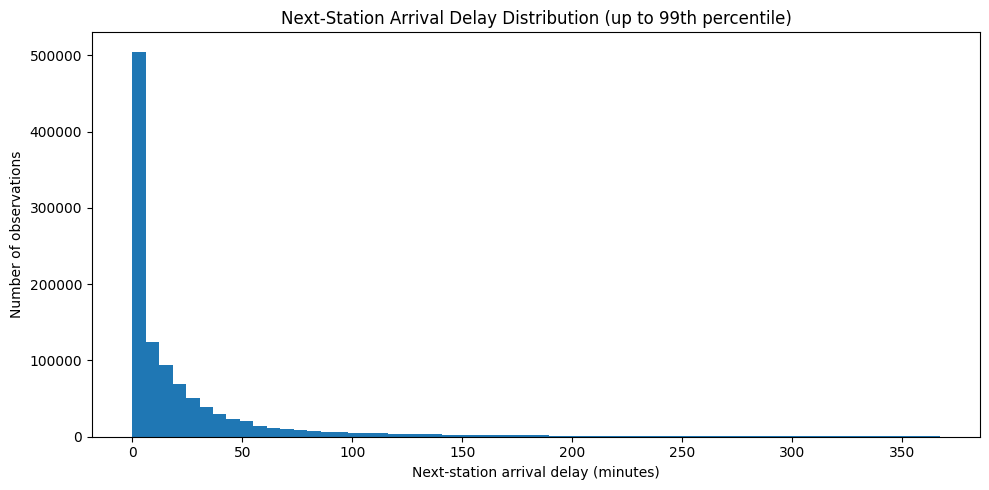

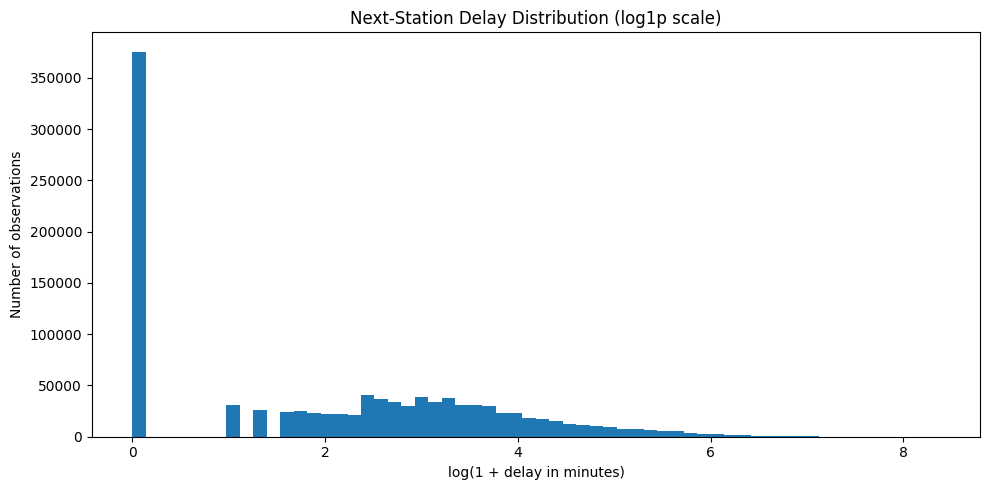

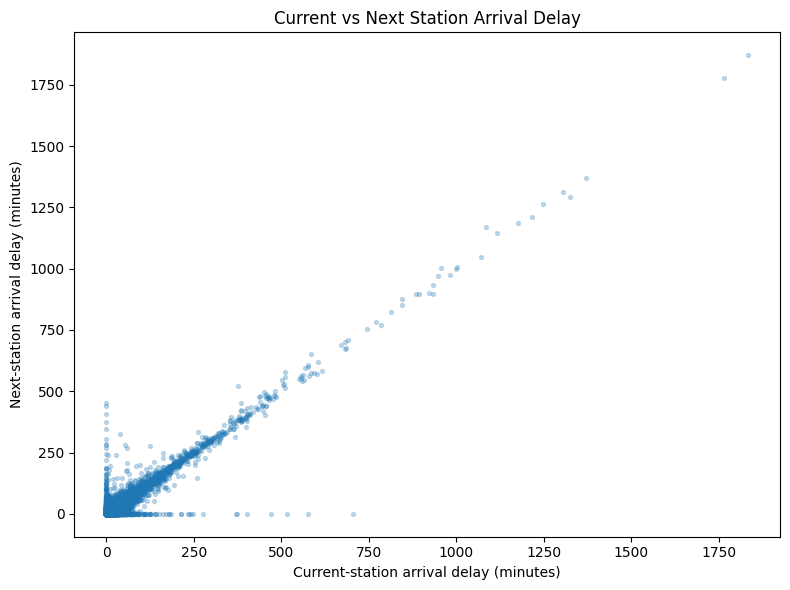

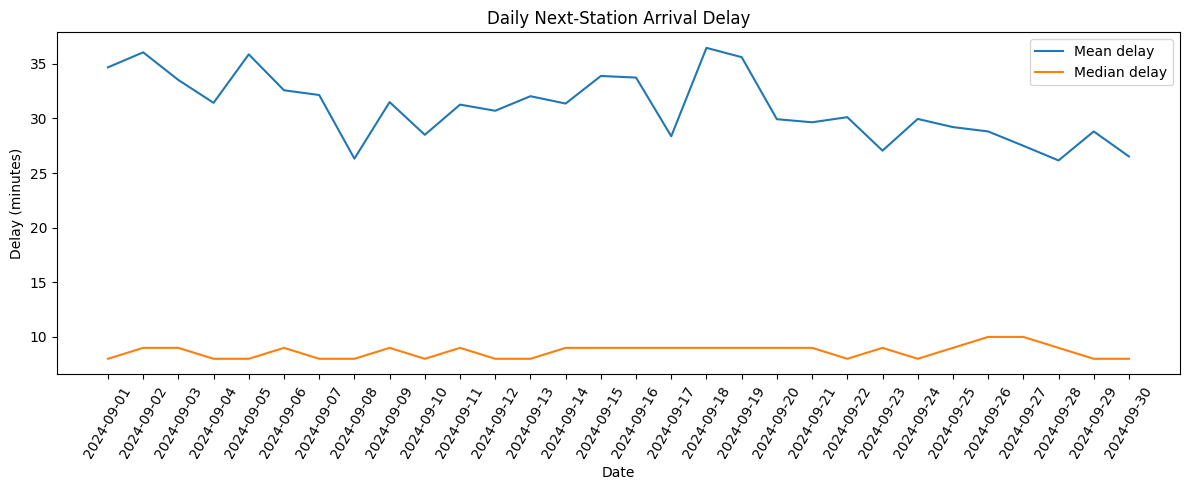


DELAY CATEGORY DISTRIBUTION
delay_category  observations  percentage
   On time (0)        375594   34.100176
      1-15 min        305234   27.712192
     16-60 min        287882   26.136804
    61-180 min         94754    8.602715
   181-720 min         35787    3.249101
 Above 720 min          2192    0.199012

TOP 20 LARGEST NEXT-STATION DELAYS
 train       date current_station next_station  current_arr_delay  next_arr_delay
 13484 2024-09-22             EKI         BNDP             4322.0          4336.0
 13484 2024-09-22            BNDP         GRMP             4336.0          4333.0
 13484 2024-09-22            MLDT          EKI                0.0          4322.0
 12601 2024-09-20             KPD          JTJ               21.0          2931.0
 12670 2024-09-02             JBP          PPI             2807.0          2855.0
 12670 2024-09-02             NGP         SEGM             2829.0          2849.0
 12670 2024-09-02            SEGM           CD             2849.0         

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = "../data/processed/railpulse_next_station_pairs.csv"

os.makedirs("../outputs/figures", exist_ok=True)
os.makedirs("../outputs/tables", exist_ok=True)

target_parts = []
current_parts = []
daily_parts = []
top_outliers = []
scatter_samples = []

rng = np.random.default_rng(42)

for chunk in pd.read_csv(
    path,
    chunksize=100_000,
    usecols=[
        "train", "date",
        "current_station", "next_station",
        "current_arr_delay", "next_arr_delay"
    ]
):
    y = chunk["next_arr_delay"].to_numpy(dtype=float)
    x = chunk["current_arr_delay"].to_numpy(dtype=float)

    target_parts.append(y)
    current_parts.append(x)

    # Daily summary
    daily_parts.append(
        chunk.groupby("date")["next_arr_delay"]
        .agg(["count", "mean", "median"])
    )

    # Keep a reproducible random sample for scatter plot
    sample_n = min(1000, len(chunk))
    sample_idx = rng.choice(len(chunk), sample_n, replace=False)

    scatter_samples.append(
        chunk.iloc[sample_idx][
            ["current_arr_delay", "next_arr_delay"]
        ]
    )

    # Keep only the largest 20 observations seen so far
    extreme = chunk.nlargest(20, "next_arr_delay")[
        [
            "train", "date", "current_station",
            "next_station", "current_arr_delay",
            "next_arr_delay"
        ]
    ]

    top_outliers.append(extreme)

y = np.concatenate(target_parts)
x = np.concatenate(current_parts)

daily = pd.concat(daily_parts).groupby(level=0).sum()
daily["mean"] = (
    pd.concat(daily_parts)["mean"]
    .groupby(level=0).mean()
)
daily["median"] = (
    pd.concat(daily_parts)["median"]
    .groupby(level=0).mean()
)

# Exact daily statistics from the full dataset
daily = pd.read_csv(path, usecols=["date", "next_arr_delay"])
daily_summary = daily.groupby("date")["next_arr_delay"].agg(
    pair_count="count",
    mean_delay="mean",
    median_delay="median"
).reset_index()

# Largest target observations
outliers = (
    pd.concat(top_outliers)
    .nlargest(20, "next_arr_delay")
    .reset_index(drop=True)
)

outliers.to_csv(
    "../outputs/tables/top_20_delay_observations.csv",
    index=False
)

daily_summary.to_csv(
    "../outputs/tables/daily_delay_summary.csv",
    index=False
)

# --------------------------------------------------
# FIGURE 1: Target distribution, capped at 99th percentile
# --------------------------------------------------

p99 = np.percentile(y, 99)

plt.figure(figsize=(10, 5))
plt.hist(y[y <= p99], bins=60)
plt.title("Next-Station Arrival Delay Distribution (up to 99th percentile)")
plt.xlabel("Next-station arrival delay (minutes)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.savefig(
    "../outputs/figures/01_target_distribution.png",
    dpi=150
)
plt.show()

# --------------------------------------------------
# FIGURE 2: Full target distribution on log scale
# --------------------------------------------------

plt.figure(figsize=(10, 5))
plt.hist(np.log1p(y), bins=60)
plt.title("Next-Station Delay Distribution (log1p scale)")
plt.xlabel("log(1 + delay in minutes)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.savefig(
    "../outputs/figures/02_target_log_distribution.png",
    dpi=150
)
plt.show()

# --------------------------------------------------
# FIGURE 3: Current vs next station delay
# --------------------------------------------------

scatter = pd.concat(scatter_samples, ignore_index=True)

plt.figure(figsize=(8, 6))
plt.scatter(
    scatter["current_arr_delay"],
    scatter["next_arr_delay"],
    alpha=0.25,
    s=8
)
plt.xlabel("Current-station arrival delay (minutes)")
plt.ylabel("Next-station arrival delay (minutes)")
plt.title("Current vs Next Station Arrival Delay")
plt.tight_layout()
plt.savefig(
    "../outputs/figures/03_delay_relationship.png",
    dpi=150
)
plt.show()

# --------------------------------------------------
# FIGURE 4: Daily median and mean delay
# --------------------------------------------------

plt.figure(figsize=(12, 5))
plt.plot(
    daily_summary["date"],
    daily_summary["mean_delay"],
    label="Mean delay"
)
plt.plot(
    daily_summary["date"],
    daily_summary["median_delay"],
    label="Median delay"
)
plt.xticks(rotation=60)
plt.xlabel("Date")
plt.ylabel("Delay (minutes)")
plt.title("Daily Next-Station Arrival Delay")
plt.legend()
plt.tight_layout()
plt.savefig(
    "../outputs/figures/04_daily_delay_trend.png",
    dpi=150
)
plt.show()

# --------------------------------------------------
# Delay category analysis
# --------------------------------------------------

bins = [-0.001, 0, 15, 60, 180, 720, float("inf")]
labels = [
    "On time (0)",
    "1-15 min",
    "16-60 min",
    "61-180 min",
    "181-720 min",
    "Above 720 min"
]

categories = pd.cut(y, bins=bins, labels=labels)

category_counts = (
    pd.Series(categories)
    .value_counts(sort=False)
    .rename_axis("delay_category")
    .reset_index(name="observations")
)

category_counts["percentage"] = (
    category_counts["observations"] / len(y) * 100
)

category_counts.to_csv(
    "../outputs/tables/delay_categories.csv",
    index=False
)

print("\nDELAY CATEGORY DISTRIBUTION")
print(category_counts.to_string(index=False))

print("\nTOP 20 LARGEST NEXT-STATION DELAYS")
print(outliers.to_string(index=False))

print("\nDAILY SUMMARY")
print(daily_summary.describe().round(2).to_string())

print("\nEDA FILES SAVED")
print("Figures: ../outputs/figures/")
print("Tables: ../outputs/tables/")


In [16]:

import sqlite3
import pandas as pd

db_path = "../data/interim/railpulse_pairing.db"
conn = sqlite3.connect(db_path)

cases = [
    ("13484", "2024-09-22"),
    ("12601", "2024-09-20"),
    ("12670", "2024-09-02")
]

for train, date in cases:
    print("\n" + "=" * 85)
    print(f"TRAIN {train} | DATE {date}")
    print("=" * 85)

    result = pd.read_sql_query("""
        SELECT
            d.train,
            d.date,
            r.stnSerialNumber,
            d.station,
            r.next_station,
            d.sch_arr,
            d.act_arr,
            d.arr_delay,
            d.sch_dep,
            d.act_dep,
            d.dep_delay,
            n.arr_delay AS next_arr_delay
        FROM delay_obs d
        LEFT JOIN route_transitions r
            ON d.train = r.trainNumber
            AND d.station = r.station_code
        LEFT JOIN delay_obs n
            ON n.train = d.train
            AND n.date = d.date
            AND n.station = r.next_station
        WHERE d.train = ?
          AND d.date = ?
        ORDER BY r.stnSerialNumber
    """, conn, params=(train, date))

    print("Station observations:", len(result))
    print(result.to_string(index=False))

conn.close()

print("\nOUTLIER INVESTIGATION COMPLETED")



TRAIN 13484 | DATE 2024-09-22
Station observations: 71
train       date  stnSerialNumber station next_station  sch_arr  act_arr  arr_delay  sch_dep  act_dep  dep_delay  next_arr_delay
13484 2024-09-22              NaN    BLGT          NaN 12:55 PM 12:55 PM        0.0 12:55 PM 12:55 PM        0.0             NaN
13484 2024-09-22              1.0     BTI          JHL 04:25 PM 04:25 PM        0.0 04:25 PM 04:25 PM        0.0             0.0
13484 2024-09-22              2.0     JHL          TUN 05:29 PM 05:30 PM        0.0 05:31 PM 05:32 PM        0.0             0.0
13484 2024-09-22              3.0     TUN          NRW 05:42 PM 05:43 PM        0.0 05:44 PM 05:45 PM        0.0             2.0
13484 2024-09-22              4.0     NRW         JIND 06:03 PM 06:05 PM        2.0 06:05 PM 06:07 PM        2.0             0.0
13484 2024-09-22              5.0    JIND          ROK 06:33 PM 06:33 PM        0.0 06:35 PM 06:35 PM        0.0             8.0
13484 2024-09-22              6.0     ROK

In [17]:

import pandas as pd
import numpy as np

path = "../data/processed/railpulse_next_station_pairs.csv"

chunks = []
for chunk in pd.read_csv(
    path,
    chunksize=100_000,
    usecols=[
        "train", "date", "current_station",
        "next_station", "current_arr_delay",
        "next_arr_delay"
    ]
):
    chunks.append(chunk)

df = pd.concat(chunks, ignore_index=True)

# Change in reported delay between consecutive stations
df["delay_change"] = (
    df["next_arr_delay"] - df["current_arr_delay"]
)

# Absolute change
df["absolute_change"] = df["delay_change"].abs()

# Flag major jumps and resets
df["extreme_jump"] = df["absolute_change"] >= 720

df["extreme_reset"] = (
    (df["current_arr_delay"] >= 720) &
    (df["next_arr_delay"] <= 60)
)

df["extreme_increase"] = (
    (df["next_arr_delay"] >= 720) &
    (df["current_arr_delay"] <= 60)
)

print("=" * 70)
print("GLOBAL EXTREME TRANSITION AUDIT")
print("=" * 70)

print("Total pairs:", len(df))
print("Changes >= 12 hours:", df["extreme_jump"].sum())
print("Extreme resets:", df["extreme_reset"].sum())
print("Extreme increases:", df["extreme_increase"].sum())

print("\nLargest 25 absolute delay changes:")
print(
    df.nlargest(25, "absolute_change")[
        [
            "train", "date", "current_station", "next_station",
            "current_arr_delay", "next_arr_delay",
            "delay_change"
        ]
    ].to_string(index=False)
)

print("\nLargest extreme increases:")
print(
    df[df["extreme_increase"]]
    .nlargest(20, "next_arr_delay")[
        [
            "train", "date", "current_station", "next_station",
            "current_arr_delay", "next_arr_delay"
        ]
    ].to_string(index=False)
)

print("\nLargest extreme resets:")
print(
    df[df["extreme_reset"]]
    .nlargest(20, "current_arr_delay")[
        [
            "train", "date", "current_station", "next_station",
            "current_arr_delay", "next_arr_delay"
        ]
    ].to_string(index=False)
)

# Save flagged observations for review
flagged = df[
    df["extreme_jump"]
].copy()

flagged.to_csv(
    "../outputs/tables/extreme_transition_audit.csv",
    index=False
)

print("\nSaved extreme transition audit.")


GLOBAL EXTREME TRANSITION AUDIT
Total pairs: 1101443
Changes >= 12 hours: 263
Extreme resets: 124
Extreme increases: 135

Largest 25 absolute delay changes:
 train       date current_station next_station  current_arr_delay  next_arr_delay  delay_change
 13484 2024-09-22            GRMP         BLGT             4333.0             0.0       -4333.0
 13484 2024-09-22            MLDT          EKI                0.0          4322.0        4322.0
 12601 2024-09-20             KPD          JTJ               21.0          2931.0        2910.0
 12601 2024-09-20             JTJ           SA             2931.0            22.0       -2909.0
 12670 2024-09-02            SKZR           WL             2810.0             0.0       -2810.0
 12416 2024-09-16            NDLS          NZM                0.0          2202.0        2202.0
 12416 2024-09-16             NZM          MTJ             2202.0             0.0       -2202.0
 12295 2024-09-05             DDU          DLN             1866.0          

In [18]:

import pandas as pd
import numpy as np
import sqlite3
import os

audit_path = "../outputs/tables/extreme_transition_audit.csv"
db_path = "../data/interim/railpulse_pairing.db"

flagged = pd.read_csv(
    audit_path,
    dtype={"train": str, "date": str}
)

conn = sqlite3.connect(db_path)

# Load the 263 flagged transitions into SQLite
conn.execute("DROP TABLE IF EXISTS flagged_pairs")

flagged.to_sql(
    "flagged_pairs",
    conn,
    if_exists="replace",
    index=False
)

# Retrieve original scheduled and actual arrival clocks
check = pd.read_sql_query("""
    SELECT
        f.train,
        f.date,
        f.current_station,
        f.next_station,
        f.current_arr_delay,
        f.next_arr_delay,
        f.delay_change,

        d.sch_arr AS current_sch,
        d.act_arr AS current_act,

        n.sch_arr AS next_sch,
        n.act_arr AS next_act

    FROM flagged_pairs f

    LEFT JOIN delay_obs d
        ON d.train = f.train
        AND d.date = f.date
        AND d.station = f.current_station

    LEFT JOIN delay_obs n
        ON n.train = f.train
        AND n.date = f.date
        AND n.station = f.next_station
""", conn)

conn.close()

def clock_minutes(value):
    if pd.isna(value):
        return np.nan

    parsed = pd.to_datetime(
        str(value).strip(),
        format="%I:%M %p",
        errors="coerce"
    )

    if pd.isna(parsed):
        return np.nan

    return parsed.hour * 60 + parsed.minute

for prefix in ["current", "next"]:
    sch = check[f"{prefix}_sch"].apply(clock_minutes)
    act = check[f"{prefix}_act"].apply(clock_minutes)

    # Difference modulo 24 hours
    check[f"{prefix}_clock_delay_mod"] = (
        (act - sch) % 1440
    )

    check[f"{prefix}_reported_mod"] = (
        check[f"{prefix}_arr_delay"] % 1440
    )

    check[f"{prefix}_clock_match"] = (
        check[f"{prefix}_clock_delay_mod"] ==
        check[f"{prefix}_reported_mod"]
    )

# --------------------------------------------------
# Summary
# --------------------------------------------------

print("=" * 70)
print("EXTREME DELAY CLOCK-CONSISTENCY AUDIT")
print("=" * 70)

print("Flagged transitions:", len(check))

print(
    "Current delay matches clock modulo:",
    check["current_clock_match"].sum()
)

print(
    "Next delay matches clock modulo:",
    check["next_clock_match"].sum()
)

print(
    "Both current and next match:",
    (
        check["current_clock_match"] &
        check["next_clock_match"]
    ).sum()
)

print(
    "Either side fails clock consistency:",
    (
        ~check["current_clock_match"] |
        ~check["next_clock_match"]
    ).sum()
)

# --------------------------------------------------
# Separate increases, resets and other transitions
# --------------------------------------------------

check["transition_type"] = np.select(
    [
        (check["current_arr_delay"] <= 60) &
        (check["next_arr_delay"] >= 720),

        (check["current_arr_delay"] >= 720) &
        (check["next_arr_delay"] <= 60)
    ],
    [
        "Extreme increase",
        "Extreme reset"
    ],
    default="Other extreme change"
)

print("\nCLOCK CONSISTENCY BY TRANSITION TYPE")

summary = check.groupby("transition_type").agg(
    records=("train", "size"),
    both_clock_match=(
        "current_clock_match",
        "sum"
    )
)

summary["both_clock_match"] = check.groupby(
    "transition_type"
).apply(
    lambda x: (
        x["current_clock_match"] &
        x["next_clock_match"]
    ).sum(),
    include_groups=False
)

print(summary.to_string())

# --------------------------------------------------
# Show examples that fail clock consistency
# --------------------------------------------------

failed = check[
    ~check["current_clock_match"] |
    ~check["next_clock_match"]
].copy()

print("\nFIRST 25 CLOCK-INCONSISTENT TRANSITIONS")

print(
    failed[
        [
            "train", "date",
            "current_station", "next_station",
            "current_arr_delay", "next_arr_delay",
            "current_sch", "current_act",
            "next_sch", "next_act",
            "current_clock_match", "next_clock_match"
        ]
    ].head(25).to_string(index=False)
)

# Save full audit
check.to_csv(
    "../outputs/tables/extreme_clock_consistency.csv",
    index=False
)

print("\nSaved extreme_clock_consistency.csv")
print("\nAUDIT COMPLETED")


EXTREME DELAY CLOCK-CONSISTENCY AUDIT
Flagged transitions: 263
Current delay matches clock modulo: 262
Next delay matches clock modulo: 263
Both current and next match: 262
Either side fails clock consistency: 1

CLOCK CONSISTENCY BY TRANSITION TYPE
                      records  both_clock_match
transition_type                                
Extreme increase          135               134
Extreme reset             124               124
Other extreme change        4                 4

FIRST 25 CLOCK-INCONSISTENT TRANSITIONS
train       date current_station next_station  current_arr_delay  next_arr_delay current_sch current_act next_sch next_act  current_clock_match  next_clock_match
12662 2024-09-03              DG          TPJ                0.0           921.0    10:32 PM    10:33 PM 11:50 PM 03:11 PM                False              True

Saved extreme_clock_consistency.csv

AUDIT COMPLETED
